# TED 03 — Modelagem Preditiva e Machine Learning

Regressão da remuneração média mensal (`valor_remuneracao_media`) de trabalhadores formais da construção civil no Maranhão (RAIS 2023) como referência salarial para o projeto Conserpav.

**Instruções de execução:**
```bash
cd projeto
pip install -r requirements.txt
cd src
jupyter notebook TED03.ipynb
```

In [1]:
# 1. Importação das bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

SEED = 42  # semente única para divisão, validação cruzada e amostragens

## 1. Dados
Carregamento da base de dados da RAIS 2023 para a construção civil no Maranhão.

In [2]:
# 2. Carregamento da base de dados (RAIS 2023 - Construção Civil MA)
df = pd.read_csv('../data/base_de_dados.csv', sep=',', decimal='.', encoding='latin-1')
df.columns = df.columns.str.strip()
print(f"Base inicial: {df.shape[0]} registros | {df.shape[1]} colunas")

Base inicial: 97971 registros | 67 colunas


## 2. Limpeza herdada da TED 02
Remoção das 12 colunas sem variação, obsoletas ou específicas de outras UFs descartadas na TED 02 (listadas nos comentários do código).

In [3]:
# 3. Remoção das 12 colunas descartadas na TED 02
colunas_remover = [
    # 5 colunas 100% vazias
    'tipo_salario', 'valor_salario_contratual', 'subatividade_ibge',
    'cbo_1994', 'grau_instrucao_1985_2005',
    # 5 colunas de localidades fora do Maranhão
    'bairros_sp', 'distritos_sp', 'bairros_fortaleza', 'bairros_rj',
    'regioes_administrativas_df',
    # constante no recorte / quase totalmente nula
    'ano_chegada_brasil', 'id_municipio_trabalho'
]

df_trabalho = df.drop(columns=colunas_remover)
assert len(colunas_remover) == 12 and df_trabalho.shape[1] == 55
print(f"Após remoção de colunas: {df_trabalho.shape[0]} registros | {df_trabalho.shape[1]} colunas")

Após remoção de colunas: 97971 registros | 55 colunas


## 3. Preparação — decisões para modelagem
Duplicidades e remunerações zeradas foram excluídas apenas para o treino dos modelos (diferente da TED 02), para evitar distorções no ajuste. O efeito dessas decisões sobre as métricas é avaliado na seção 13.

In [4]:
# 4. Decisões específicas da TED 03: duplicidades e remuneração > 0
duplicatas = df_trabalho.duplicated().sum()
df_trabalho = df_trabalho.drop_duplicates()
print(f"Duplicatas removidas: {duplicatas}")

n_antes = len(df_trabalho)
df_modelo = df_trabalho[df_trabalho['valor_remuneracao_media'] > 0].copy()
print(f"Vínculos com remuneração = 0 excluídos: {n_antes - len(df_modelo)}")
print(f"Registros válidos para treino/teste (remuneração > 0): {df_modelo.shape[0]}")

Duplicatas removidas: 543


Vínculos com remuneração = 0 excluídos: 11673
Registros válidos para treino/teste (remuneração > 0): 85755


## 4. Seleção de variáveis
Seleção de 8 variáveis preditoras alinhadas aos campos do MVP (ocupação, setor, sexo, porte, vínculo, idade, horas e tempo no emprego), livres de vazamento de dados.

In [5]:
# 5. Definição das variáveis preditoras (X) e alvo (y)
variaveis_categoricas = ['cbo_2002', 'cnae_2', 'sexo', 'tamanho_estabelecimento', 'tipo_vinculo']
variaveis_numericas = ['idade', 'quantidade_horas_contratadas', 'tempo_emprego']
variavel_alvo = 'valor_remuneracao_media'

# Conversão das variáveis categóricas para string (são códigos, não quantidades)
for col in variaveis_categoricas:
    df_modelo[col] = df_modelo[col].astype(str)

X = df_modelo[variaveis_categoricas + variaveis_numericas]
y = df_modelo[variavel_alvo]

print(f"X shape: {X.shape} | y shape: {y.shape}")
print("\nCategorias por variável categórica:")
print(X[variaveis_categoricas].nunique().to_string())
print("\nEstatísticas do alvo (R$):")
print(y.describe(percentiles=[.5, .9, .99]).round(2).to_string())
print(f"Assimetria (skew): {y.skew():.2f}")

X shape: (85755, 8) | y shape: (85755,)

Categorias por variável categórica:
cbo_2002                   719
cnae_2                      19
sexo                         2
tamanho_estabelecimento     10
tipo_vinculo                15

Estatísticas do alvo (R$):


count    85755.00
mean      2364.39
std       1686.44
min          1.00
50%       1973.40
90%       3856.09
99%       8849.03
max      72837.96
Assimetria (skew): 6.28


## 5. Divisão treino/teste
Divisão aleatória em 80% para treino e 20% para teste (`random_state=42`), mantendo o conjunto de teste isolado para a avaliação final.

In [6]:
# 6. Divisão dos dados em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=SEED
)

print(f"Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")

Treino: 68604 amostras | Teste: 17151 amostras


## 6. Pré-processamento
Transformação via `ColumnTransformer` com `OneHotEncoder(handle_unknown='ignore')` para atributos categóricos e `SimpleImputer(strategy='median')` para numéricos dentro do Pipeline.

In [7]:
# 7. Configuração do pré-processamento via ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), variaveis_categoricas),
        ('num', SimpleImputer(strategy='median'), variaveis_numericas)
    ],
    remainder='drop'
)

## 7. Modelos
Construção dos pipelines do baseline (`DummyRegressor`, que prevê a média do treino) e do modelo principal (`LinearRegression`).

In [8]:
# 8. Criação e treinamento dos pipelines (Baseline e Regressão Linear)
pipeline_baseline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', DummyRegressor(strategy='mean'))
])

pipeline_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

pipeline_baseline.fit(X_train, y_train)
pipeline_lr.fit(X_train, y_train)
print("Treinamento dos modelos concluído.")
print(f"Colunas de entrada após o One-Hot Encoding: {len(pipeline_lr.named_steps['preprocessor'].get_feature_names_out())}")

Treinamento dos modelos concluído.
Colunas de entrada após o One-Hot Encoding: 742


## 8. Métricas de avaliação (teste)
Cálculo das métricas MAE, MSE, RMSE e R² no conjunto de teste independente.

In [9]:
# 9. Previsões e cálculo das métricas de avaliação (conjunto de teste)
y_pred_baseline = pipeline_baseline.predict(X_test)
y_pred_lr = pipeline_lr.predict(X_test)

def calcular_metricas(y_real, y_pred, nome_modelo):
    mae = mean_absolute_error(y_real, y_pred)
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_real, y_pred)
    return {
        'Modelo': nome_modelo,
        'MAE (R$)': round(mae, 2),
        'MSE': round(mse, 2),
        'RMSE (R$)': round(rmse, 2),
        'R²': round(r2, 4) + 0.0
    }

metricas_baseline = calcular_metricas(y_test, y_pred_baseline, 'DummyRegressor (Baseline)')
metricas_lr = calcular_metricas(y_test, y_pred_lr, 'LinearRegression')

df_resultados = pd.DataFrame([metricas_baseline, metricas_lr]).set_index('Modelo')
print("=== COMPARAÇÃO DOS MODELOS (TESTE) ===")
print(df_resultados.to_string())

ganho_mae = (metricas_baseline['MAE (R$)'] - metricas_lr['MAE (R$)']) / metricas_baseline['MAE (R$)']
ganho_rmse = (metricas_baseline['RMSE (R$)'] - metricas_lr['RMSE (R$)']) / metricas_baseline['RMSE (R$)']
print(f"\nRedução do MAE sobre o baseline: {ganho_mae:.1%} | Redução do RMSE: {ganho_rmse:.1%}")
print(f"MAE / média do alvo: {metricas_lr['MAE (R$)'] / y_test.mean():.1%} | MAE / mediana do alvo: {metricas_lr['MAE (R$)'] / y_test.median():.1%}")

=== COMPARAÇÃO DOS MODELOS (TESTE) ===
                           MAE (R$)         MSE  RMSE (R$)     R²
Modelo                                                           
DummyRegressor (Baseline)    995.09  2846010.87    1687.01  0.000
LinearRegression             634.03  1494122.98    1222.34  0.475

Redução do MAE sobre o baseline: 36.3% | Redução do RMSE: 27.5%
MAE / média do alvo: 26.8% | MAE / mediana do alvo: 32.1%


## 9. Generalização: treino × teste e validação cruzada
Comparação das métricas entre treino e teste e validação cruzada em 5 partes para verificar a estabilidade do modelo e ausência de sobreajuste.

In [10]:
# 10. Verificação de sobreajuste: treino x teste e validação cruzada (5 partes)
y_pred_treino = pipeline_lr.predict(X_train)
tab_gen = pd.DataFrame({
    'R²': [r2_score(y_train, y_pred_treino), r2_score(y_test, y_pred_lr)],
    'MAE (R$)': [mean_absolute_error(y_train, y_pred_treino), mean_absolute_error(y_test, y_pred_lr)]
}, index=['Treino', 'Teste']).round(4)
print(tab_gen.to_string())

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_r2 = cross_val_score(pipeline_lr, X, y, cv=kf, scoring='r2')
cv_mae = -cross_val_score(pipeline_lr, X, y, cv=kf, scoring='neg_mean_absolute_error')
print(f"\nValidação cruzada (5 partes) - R²: {np.round(cv_r2, 4)} | média {cv_r2.mean():.4f} (desvio {cv_r2.std():.4f})")
print(f"Validação cruzada (5 partes) - MAE: {np.round(cv_mae, 1)} | média R$ {cv_mae.mean():.2f}")

            R²  MAE (R$)
Treino  0.5244  614.9832
Teste   0.4750  634.0261



Validação cruzada (5 partes) - R²: [0.475  0.4578 0.5044 0.4975 0.4736] | média 0.4817 (desvio 0.0170)
Validação cruzada (5 partes) - MAE: [634.  628.  617.7 628.3 640.9] | média R$ 629.79


## 10. Análise dos erros
Inspeção do comportamento dos erros por faixa salarial e resíduos medianos.

In [11]:
# 11. Análise dos erros: faixas de remuneração, erro mediano e previsões inválidas
residuos = y_test.values - y_pred_lr
erro_abs = np.abs(residuos)

faixas = pd.cut(y_test, bins=[0, 1500, 2500, 5000, np.inf],
                labels=['Até R$ 1.500', 'R$ 1.500 a 2.500', 'R$ 2.500 a 5.000', 'Acima de R$ 5.000'])
tab_faixas = pd.DataFrame({'faixa': faixas.values, 'erro_abs': erro_abs, 'residuo': residuos}) \
    .groupby('faixa', observed=True) \
    .agg(registros=('erro_abs', 'size'), MAE=('erro_abs', 'mean'), residuo_medio=('residuo', 'mean')).round(2)
print(tab_faixas.to_string())

print(f"\nErro absoluto mediano: R$ {np.median(erro_abs):,.2f}")
print(f"Erro percentual absoluto mediano: {np.median(erro_abs / y_test.values):.1%}")
print(f"Previsões com erro de até R$ 300: {(erro_abs <= 300).mean():.1%}")
print(f"Previsões negativas: {(y_pred_lr < 0).sum()} (mínimo: R$ {y_pred_lr.min():,.2f})")

                   registros      MAE  residuo_medio
faixa                                               
Até R$ 1.500            4933   482.36        -342.88
R$ 1.500 a 2.500        6761   445.55        -184.61
R$ 2.500 a 5.000        4647   662.53         195.18
Acima de R$ 5.000        810  2967.36        2644.40

Erro absoluto mediano: R$ 373.94
Erro percentual absoluto mediano: 18.8%
Previsões com erro de até R$ 300: 41.8%
Previsões negativas: 8 (mínimo: R$ -780.73)


## 11. Coeficientes do modelo
Identificação dos pesos estimados para atributos numéricos e ocupações (CBOs).

In [12]:
# 12. Interpretação dos coeficientes (quais variáveis pesam no modelo)
nomes = pipeline_lr.named_steps['preprocessor'].get_feature_names_out()
coef = pd.Series(pipeline_lr.named_steps['regressor'].coef_, index=nomes)

print("Coeficientes das variáveis numéricas (R$ por unidade):")
print(coef[[n for n in nomes if n.startswith('num__')]].round(2).to_string())

# Ocupações (CBO) com maiores coeficientes, ao lado do nº de registros no treino
contagem_cbo = X_train['cbo_2002'].value_counts()
coef_cbo = coef[[n for n in nomes if n.startswith('cat__cbo_2002_')]].copy()
coef_cbo.index = coef_cbo.index.str.replace('cat__cbo_2002_', '', regex=False)
tab_cbo = pd.DataFrame({'coeficiente (R$)': coef_cbo, 'registros no treino': contagem_cbo.reindex(coef_cbo.index).fillna(0).astype(int)})
print("\n6 maiores coeficientes de ocupação:")
print(tab_cbo.sort_values('coeficiente (R$)', ascending=False).head(6).round(0).to_string())

print(f"\nCBOs com menos de 10 registros no recorte: {(X['cbo_2002'].value_counts() < 10).sum()} de {X['cbo_2002'].nunique()}")
print("\n6 maiores coeficientes entre CBOs com pelo menos 30 registros no treino:")
print(tab_cbo[tab_cbo['registros no treino'] >= 30].sort_values('coeficiente (R$)', ascending=False).head(6).round(0).to_string())

Coeficientes das variáveis numéricas (R$ por unidade):
num__idade                           11.35
num__quantidade_horas_contratadas     6.66
num__tempo_emprego                    5.13

6 maiores coeficientes de ocupação:
        coeficiente (R$)  registros no treino
215215           21983.0                    1
123110           15907.0                    5
142110           13386.0                    2
142510           10586.0                    1
131205            9947.0                    2
123105            9650.0                   26

CBOs com menos de 10 registros no recorte: 392 de 719

6 maiores coeficientes entre CBOs com pelo menos 30 registros no treino:
        coeficiente (R$)  registros no treino
214405            5672.0                   43
214915            4966.0                   50
141305            4477.0                  118
214205            4252.0                  398
142305            3571.0                   34
950305            3353.0                   48


## 13. Experimento: efeito das decisões sobre duplicidades e remuneração
Comparação empírica dos cenários mantendo versus removendo duplicidades e valores zerados.

In [13]:
# 13. Experimento: efeito das decisões sobre duplicidades e remuneração zero (TED 02 x TED 03)
def avaliar_cenario(base, rotulo):
    b = base.copy()
    for col in variaveis_categoricas:
        b[col] = b[col].astype(str)
    Xtr, Xte, ytr, yte = train_test_split(b[variaveis_categoricas + variaveis_numericas],
                                          b[variavel_alvo], test_size=0.2, random_state=SEED)
    pipe = Pipeline([('preprocessor', preprocessor), ('regressor', LinearRegression())]).fit(Xtr, ytr)
    p = pipe.predict(Xte)
    return {'Cenário': rotulo, 'Registros': len(b),
            'MAE (R$)': round(mean_absolute_error(yte, p), 2), 'R²': round(r2_score(yte, p), 4)}

base_sem_dup_removida = df.drop(columns=colunas_remover)  # mantém duplicidades (como na TED 02)
cenarios = pd.DataFrame([
    avaliar_cenario(base_sem_dup_removida, 'TED 02 pura: mantém duplicidades e zeros'),
    avaliar_cenario(base_sem_dup_removida[base_sem_dup_removida[variavel_alvo] > 0], 'Mantém duplicidades, exclui zeros'),
    avaliar_cenario(df_modelo, 'TED 03: remove duplicidades e exclui zeros (adotado)'),
]).set_index('Cenário')
print(cenarios.to_string())

                                                      Registros  MAE (R$)      R²
Cenário                                                                          
TED 02 pura: mantém duplicidades e zeros                  97971    779.99  0.3834
Mantém duplicidades, exclui zeros                         86131    626.59  0.4453
TED 03: remove duplicidades e exclui zeros (adotado)      85755    634.03  0.4750


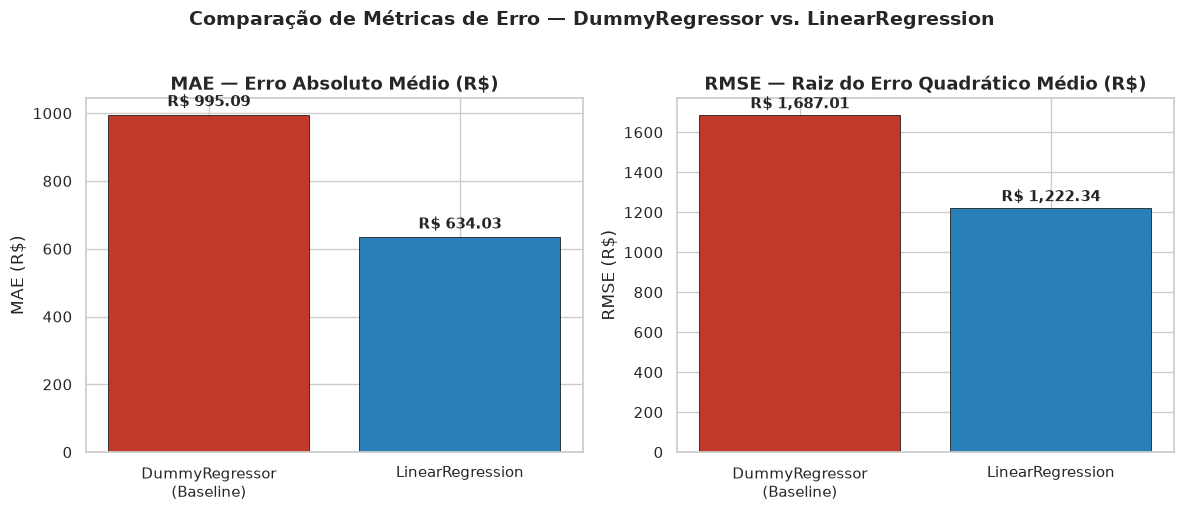

In [14]:
# 14. Gráfico 1: Comparação de MAE e RMSE entre os modelos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
modelos = ['DummyRegressor\n(Baseline)', 'LinearRegression']
cores = ['#c0392b', '#2980b9']

valores_mae = [metricas_baseline['MAE (R$)'], metricas_lr['MAE (R$)']]
bars_mae = axes[0].bar(modelos, valores_mae, color=cores, edgecolor='black', linewidth=0.5)
axes[0].set_title('MAE — Erro Absoluto Médio (R$)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('MAE (R$)')
for bar, val in zip(bars_mae, valores_mae):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
                 f'R$ {val:,.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

valores_rmse = [metricas_baseline['RMSE (R$)'], metricas_lr['RMSE (R$)']]
bars_rmse = axes[1].bar(modelos, valores_rmse, color=cores, edgecolor='black', linewidth=0.5)
axes[1].set_title('RMSE — Raiz do Erro Quadrático Médio (R$)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('RMSE (R$)')
for bar, val in zip(bars_rmse, valores_rmse):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
                 f'R$ {val:,.2f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.suptitle('Comparação de Métricas de Erro — DummyRegressor vs. LinearRegression', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../data/grafico_comparacao_metricas.png', dpi=150, bbox_inches='tight')
plt.show()

**Figura 1.** Em relação ao baseline, a regressão linear reduz o MAE de R$ 995,09 para R$ 634,03 (−36,3%) e o RMSE de R$ 1.687,01 para R$ 1.222,34 (−27,5%).

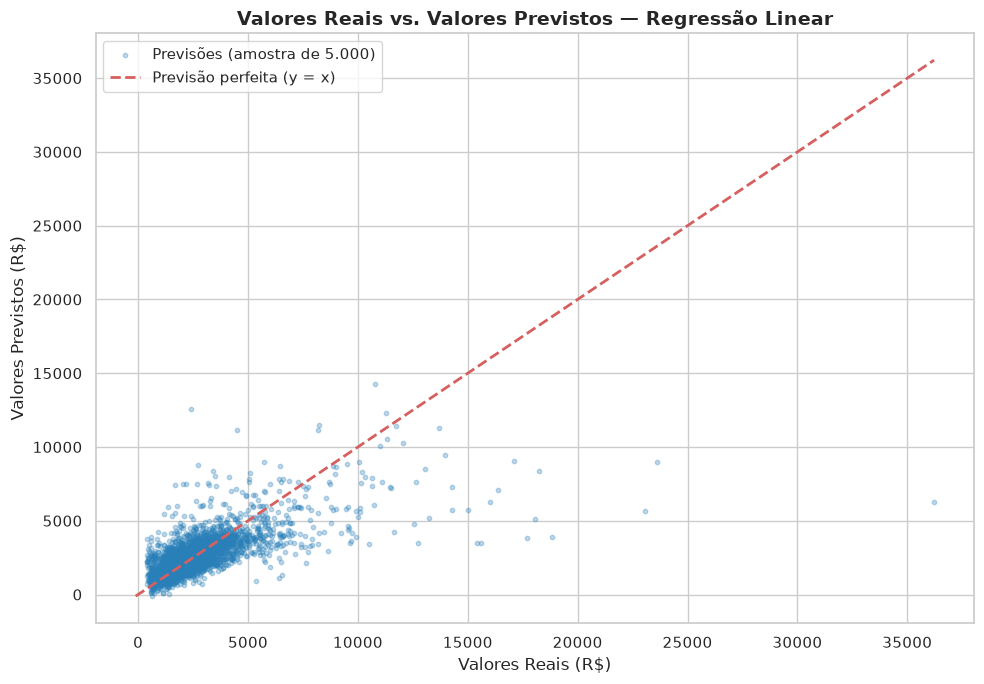

In [15]:
# 15. Gráfico 2: Valores Reais vs. Valores Previstos (LinearRegression)
fig, ax = plt.subplots(figsize=(10, 7))
n_amostra = min(5000, len(y_test))
rng = np.random.default_rng(SEED)
indices = rng.choice(len(y_test), size=n_amostra, replace=False)

y_test_amostra = y_test.iloc[indices]
y_pred_amostra = y_pred_lr[indices]

ax.scatter(y_test_amostra, y_pred_amostra, alpha=0.3, s=10, color='#2980b9', label='Previsões (amostra de 5.000)')
limite_max = max(y_test_amostra.max(), y_pred_amostra.max())
limite_min = min(y_test_amostra.min(), y_pred_amostra.min())
ax.plot([limite_min, limite_max], [limite_min, limite_max], 'r--', linewidth=2, label='Previsão perfeita (y = x)')

ax.set_xlabel('Valores Reais (R$)', fontsize=12)
ax.set_ylabel('Valores Previstos (R$)', fontsize=12)
ax.set_title('Valores Reais vs. Valores Previstos — Regressão Linear', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('../data/grafico_real_vs_previsto.png', dpi=150, bbox_inches='tight')
plt.show()

**Figura 2.** Valores reais vs. previstos pela Regressão Linear: alinhamento até R$ 5.000 e subestimação em salários mais altos.

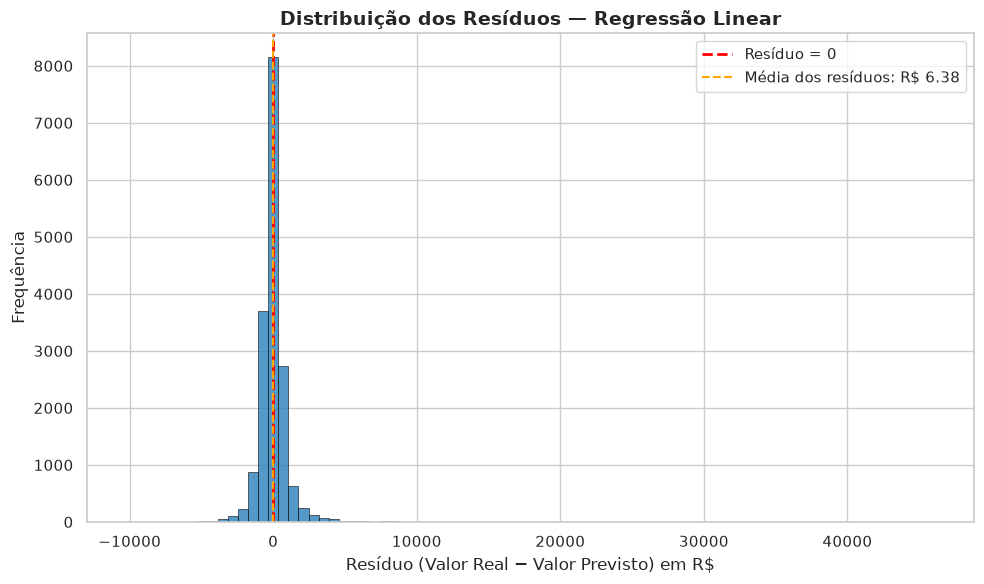

Resíduos - Média: R$ 6.38 | Mediana: R$ -44.11 | Desvio Padrão: R$ 1,222.33


In [16]:
# 16. Gráfico 3: Distribuição dos Resíduos (Valores Reais - Valores Previstos)
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(residuos, bins=80, color='#2980b9', edgecolor='black', linewidth=0.5, alpha=0.8)
ax.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Resíduo = 0')
ax.axvline(x=np.mean(residuos), color='orange', linestyle='--', linewidth=1.5,
           label=f'Média dos resíduos: R$ {np.mean(residuos):,.2f}')

ax.set_xlabel('Resíduo (Valor Real − Valor Previsto) em R$', fontsize=12)
ax.set_ylabel('Frequência', fontsize=12)
ax.set_title('Distribuição dos Resíduos — Regressão Linear', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('../data/grafico_distribuicao_residuos.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Resíduos - Média: R$ {np.mean(residuos):,.2f} | Mediana: R$ {np.median(residuos):,.2f} | Desvio Padrão: R$ {np.std(residuos):,.2f}")

**Figura 3.** Distribuição dos resíduos com média de R$ 6,38 (centrada próxima de zero), mediana de -R$ 44,11 e cauda à direita.

Interpretação, limitações e relação com o MVP: ver Documento Técnico v3.0, seções de interpretação, limitações e relação com o projeto.